# 01 — DG-TFET data generation

This notebook documents the primary dataset used in the project. The data are
generated with the **THM-TFET v1.2 physics-based compact model** (`ctfet`,
Technische Hochschule Mittelhessen), not with TCAD and not from measurements.
The compact model is first checked against the published BM1 Sentaurus TCAD
transfer characteristics; that check is reproduced at the end of this notebook.

The dataset is intentionally labelled **physics-based compact-model synthetic**
in every metadata and report file.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent
RAW = PROJECT / "data" / "raw"
PROC = PROJECT / "data" / "processed"
GRAPHS = PROJECT / "results" / "graphs"
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

meta = json.loads((RAW / "generation_metadata.json").read_text())
print("data label:", meta["data_label"])
print("model:", meta["model"])
print("devices:", meta["n_devices"])
print("bias grid:", meta["bias_grid"])
print("temperature:", meta["temperature_K"], "K —", meta["temperature_note"])

designs = pd.read_csv(RAW / "device_designs.csv")
print("\ndevice design table:", designs.shape)
display(designs.head())
display(designs.describe().T)

data label: physics-based compact-model synthetic (NOT TCAD, NOT measured)
model: THM-TFET v1.2 compact model (ctfet, THM University of Applied Sciences)
devices: 512
bias grid: {'Vgs_V': [-0.4, 1.5, 0.020000000000000018], 'Vds_V': [0.1, 0.3, 0.5]}
temperature: 300.0 K — model validated only at 300 K; T not varied

device design table: (512, 9)


,device_id,lch_nm,tox_nm,tch_nm,eps_ox,Ns_cm3,Nd_cm3,Nch_cm3,NT_cm2
0,0,22.0000,2.0000,10.0000,22.000000,1.000000e+20,1.000000e+20,1.000000e+11,1.000000e+10
1,1,31.3761,2.6175,9.7818,16.052222,8.393646e+19,1.764699e+18,1.083105e+11,2.060387e+10
2,2,32.9401,1.5259,5.7577,5.472104,8.951661e+19,3.521129e+19,1.676497e+11,1.184335e+10
3,3,21.5330,1.2558,12.1548,3.997792,6.358917e+19,1.161846e+18,1.605652e+10,2.821735e+10
4,4,25.8635,1.6319,13.6618,12.982340,5.364291e+19,4.661863e+19,8.379548e+10,6.176377e+10


,count,mean,std,min,25%,50%,75%,max
device_id,512.0,2.555000e+02,1.479459e+02,0.000000e+00,1.277500e+02,2.555000e+02,3.832500e+02,5.110000e+02
lch_nm,512.0,2.905654e+01,9.988808e+00,1.502800e+01,2.028120e+01,2.735440e+01,3.695152e+01,4.996090e+01
tox_nm,512.0,1.820786e+00,5.716733e-01,1.001600e+00,1.317475e+00,1.733650e+00,2.277325e+00,2.999400e+00
tch_nm,512.0,9.104247e+00,2.858824e+00,5.009100e+00,6.590750e+00,8.667050e+00,1.138630e+01,1.499620e+01
eps_ox,512.0,1.446484e+01,6.098829e+00,3.931867e+00,9.202603e+00,1.447247e+01,1.975370e+01,2.497264e+01
Ns_cm3,512.0,7.218989e+19,1.442880e+19,5.001774e+19,5.950236e+19,7.074368e+19,8.418157e+19,1.000000e+20
Nd_cm3,512.0,2.165381e+19,2.521845e+19,1.008690e+18,3.174424e+18,1.001382e+19,3.169147e+19,1.000000e+20
Nch_cm3,512.0,1.443536e+12,2.268963e+12,1.004908e+10,5.668160e+10,3.134489e+11,1.761191e+12,9.888455e+12
NT_cm2,512.0,2.146049e+11,2.499422e+11,1.000000e+10,3.155246e+10,9.953837e+10,3.142219e+11,9.929603e+11


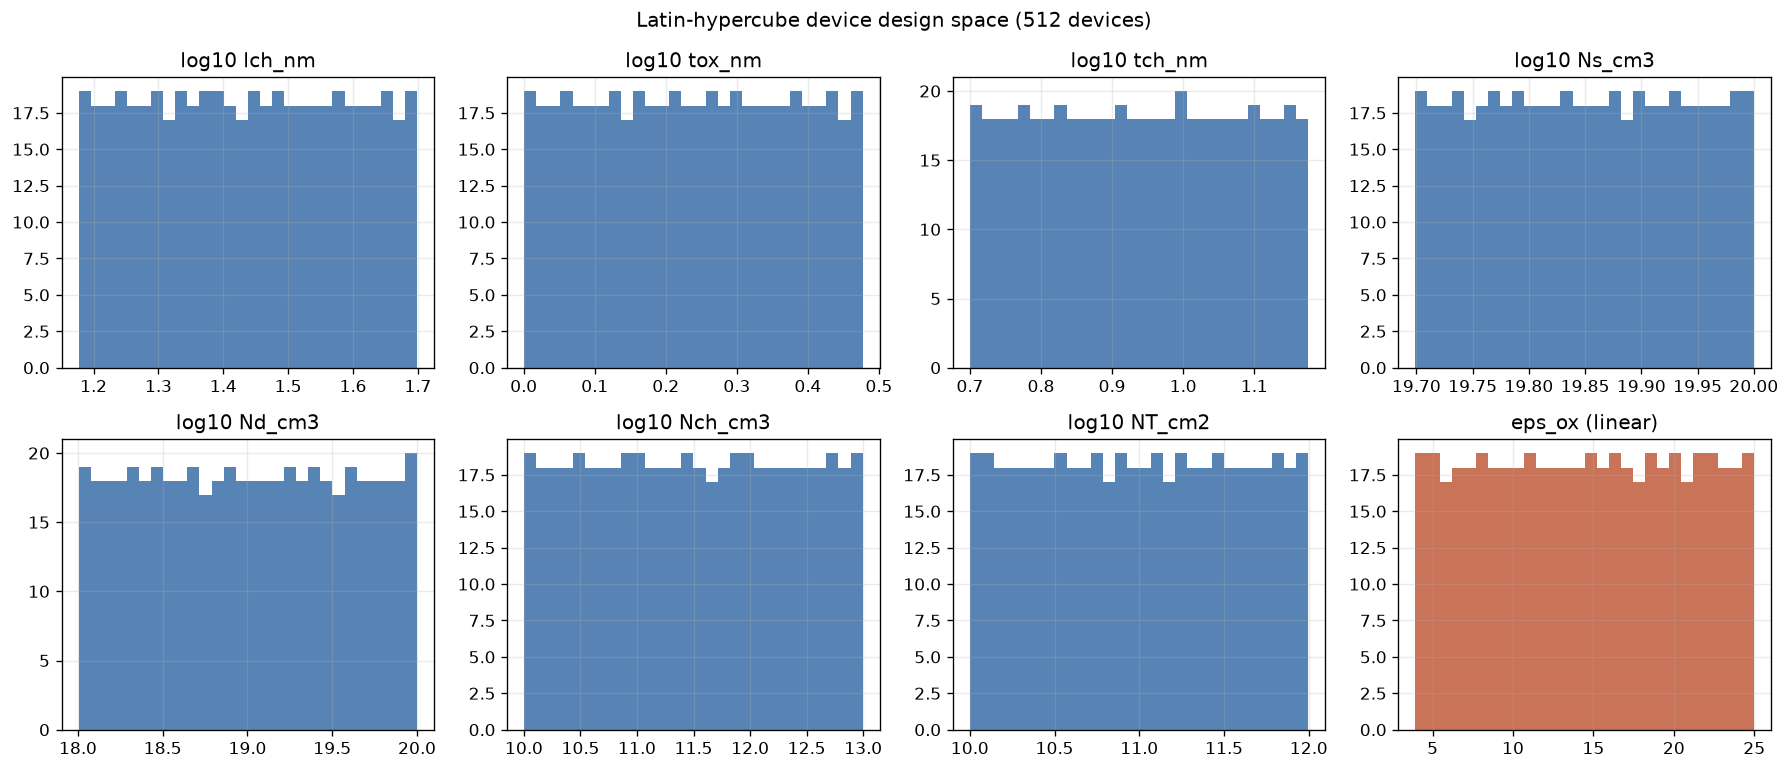

In [2]:
log_cols = ["lch_nm", "tox_nm", "tch_nm", "Ns_cm3", "Nd_cm3", "Nch_cm3", "NT_cm2"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.ravel(), log_cols):
    ax.hist(np.log10(designs[col]), bins=28, color="#3b6ea8", alpha=0.85)
    ax.set_title(f"log10 {col}")
axes.ravel()[-1].hist(designs.eps_ox, bins=28, color="#c05a3c", alpha=0.85)
axes.ravel()[-1].set_title("eps_ox (linear)")
fig.suptitle("Latin-hypercube device design space (512 devices)")
fig.tight_layout()
plt.show()

raw I-V table: (147456, 6)
missing currents: 6
rows per Vds:
Vds_V
0.1    49152
0.3    49152
0.5    49152
dtype: int64


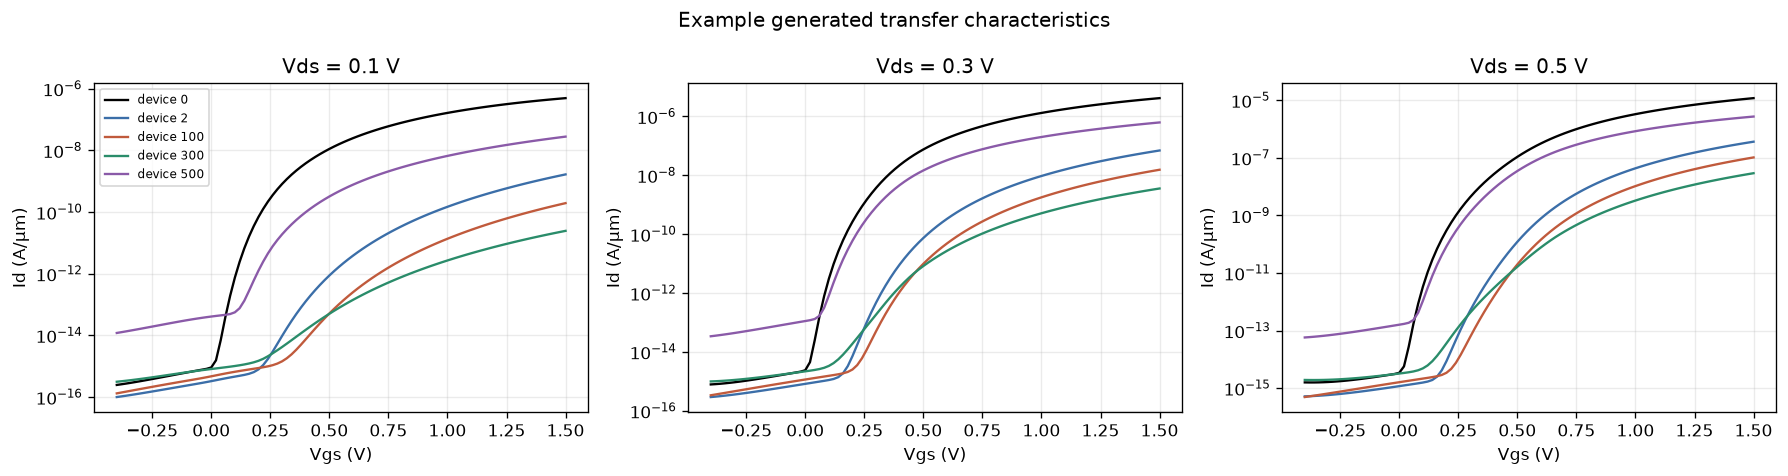

In [3]:
raw = pd.read_csv(RAW / "dg_tfet_iv_curves_raw.csv")
print("raw I-V table:", raw.shape)
print("missing currents:", int(raw["Id_A_per_um"].isna().sum()))
print("rows per Vds:")
print(raw.groupby("Vds_V").size())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, vd in zip(axes, [0.1, 0.3, 0.5]):
    for did, color in zip([0, 2, 100, 300, 500], ["k", "#3b6ea8", "#c05a3c", "#2a8c6a", "#8a5aa8"]):
        g = raw[(raw.device_id == did) & (raw.Vds_V == vd) & (raw.Id_A_per_um > 0)].sort_values("Vgs_V")
        if len(g):
            ax.plot(g.Vgs_V, g.Id_A_per_um, color=color, lw=1.4, label=f"device {did}")
    ax.set_yscale("log")
    ax.set_xlabel("Vgs (V)")
    ax.set_ylabel("Id (A/µm)")
    ax.set_title(f"Vds = {vd} V")
axes[0].legend(fontsize=7)
fig.suptitle("Example generated transfer characteristics")
fig.tight_layout()
plt.show()

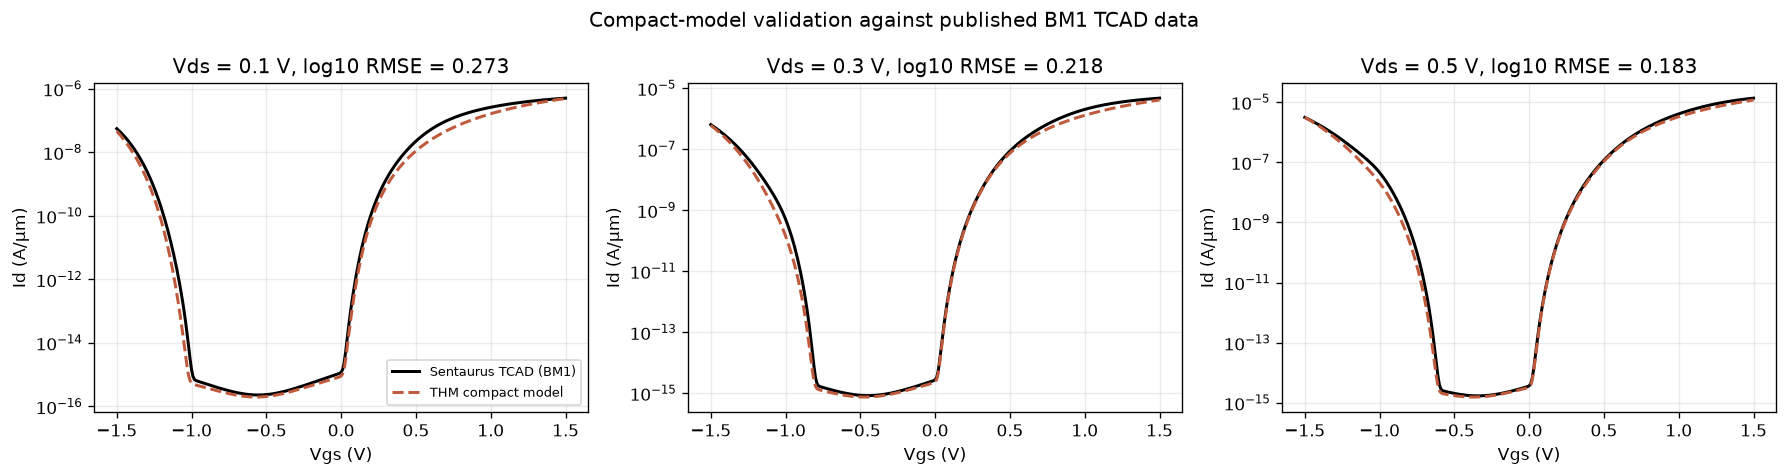

,Vds_V,log10_RMSE,n_points
0,0.1,0.273265,291
1,0.3,0.217567,291
2,0.5,0.183135,291


In [4]:
val_dir = RAW / "validation_bm1"
pairs = [("01", "010", 0.1), ("03", "030", 0.3), ("05", "050", 0.5)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rows = []
for ax, (tag, simtag, vd) in zip(axes, pairs):
    tcad = pd.read_csv(val_dir / f"BM1_ntfet_tcad_data_vds_{tag}.csv", skiprows=4)
    tcad.columns = ["Vgs", "Id"]
    sim = pd.read_csv(val_dir / f"bm1_sim_vd_{simtag}.csv", header=None, names=["Vgs", "Id"])
    common = np.intersect1d(tcad.Vgs, sim.Vgs)
    yt = np.interp(common, tcad.Vgs, tcad.Id)
    ys = np.interp(common, sim.Vgs, sim.Id)
    m = (yt > 0) & (ys > 0)
    rmse = float(np.sqrt(np.mean((np.log10(yt[m]) - np.log10(ys[m])) ** 2)))
    rows.append({"Vds_V": vd, "log10_RMSE": rmse, "n_points": int(m.sum())})
    ax.semilogy(tcad.Vgs, tcad.Id, "k-", lw=1.8, label="Sentaurus TCAD (BM1)")
    ax.semilogy(sim.Vgs, sim.Id, "--", color="#c05a3c", lw=1.8, label="THM compact model")
    ax.set_xlabel("Vgs (V)")
    ax.set_ylabel("Id (A/µm)")
    ax.set_title(f"Vds = {vd} V, log10 RMSE = {rmse:.3f}")
axes[0].legend(fontsize=8)
fig.suptitle("Compact-model validation against published BM1 TCAD data")
fig.tight_layout()
plt.show()
display(pd.DataFrame(rows))

### Data caveats

- The primary dataset is **synthetic**: it comes from a compact model, not from
  TCAD or measurements.
- The compact model is explicitly implemented for **T = 300 K**; temperature was
  not varied.
- BM1 validation is good in shape and order of magnitude, but the model is not a
  one-to-one replacement for TCAD. At `Vgs = 1.0 V` the model/TCAD current ratio
  is about 0.63 at `Vd = 0.1 V`, 0.64 at `0.3 V`, and 0.80 at `0.5 V`.
- The final 512-device design space was narrowed after an earlier broad run
  produced numerical blow-ups and many unusable curves. The narrow space is the
  one used for all models and optimization results.
- Six raw current values are NaN; they are excluded during feature extraction.